# 03 · Differential expression (DESeq2)
**Goal:** find genes whose expression differs between groups: aging (older vs 3-month mice) and each rejuvenation treatment vs its control.
**Input:** the counts of one method (set `METHOD` in the first code cell: kallisto, STAR or RSEM; notebook 04 compares them). **Output:** one table per comparison (`results/de/<METHOD>/*.csv`, regenerated, not in git).
**Kernel:** **R** (`ir`) · **Time:** ~1 min.

**Method.** kallisto estimates reads per *transcript*; the R package **tximport** sums them to *genes* and supplies average transcript lengths (RSEM's gene results are read the same way; STAR's per-gene counts are used directly). **DESeq2** then fits, for every gene, a statistical model of its read counts (counts vary more than a Poisson distribution, so it uses a negative binomial) and tests whether the **log2 fold change** (log2FC; +1 = twice as high) differs from 0. P-values are adjusted for testing ~15,000 genes at once (**padj**, Benjamini–Hochberg); a gene with padj < 0.05 is a **DEG** (differentially expressed gene). Genes with fewer than 10 reads in at least as many samples as the smallest group are not tested.

**Design.** The aging and rejuvenation mice come from different experiments (a batch effect), so they are analysed **separately**, and each treatment only against its own control:

| Analysis | Mice | Model | Comparison (log2FC direction) |
|---|---|---|---|
| Aging | 12 (3 / 18 / 21 months, 2 male + 2 female each) | `~ sex + group` | 18 vs 3, 21 vs 3 months |
| aDR | 9 females (AL 4, aDR 5) | `~ group` | aDR vs AL |
| YMP | 6 males (PBS 3, YMP 3) | `~ group` | YMP vs PBS |

`sex` is a *covariate*: included so it does not blur the age effect. Terms: [docs/glossary.md](../docs/glossary.md).

In [ ]:
# samples: one row per run; counts: gene-level counts of the chosen method; genes: gene id -> symbol (from the kallisto transcript names)
source('../R/helpers.R')
samples <- load_samples()
x <- load_txi(rownames(samples)); genes <- x$genes
METHOD <- 'kallisto'   # 'kallisto', 'STAR' or 'RSEM': which counts this notebook analyses (the choice is made in notebook 04, section 6)
txi <- switch(METHOD, kallisto = x$txi, STAR = load_star_counts()[, rownames(samples)], RSEM = load_rsem(rownames(samples)))
dir.create(file.path(ROOT, 'results/de', METHOD), recursive = TRUE, showWarnings = FALSE)
cat(METHOD, ':', if (is.matrix(txi)) nrow(txi) else nrow(txi$counts), 'genes x', nrow(samples), 'samples\n')
dplyr::count(samples, cohort, group, sex)

## 1 · All 27 samples: the cohort effect
**PCA** (principal component analysis) shows each sample as a dot; dots close together have similar whole-transcriptome profiles. PC1 (the largest source of variation) should separate the two cohorts, which is why they are not pooled.

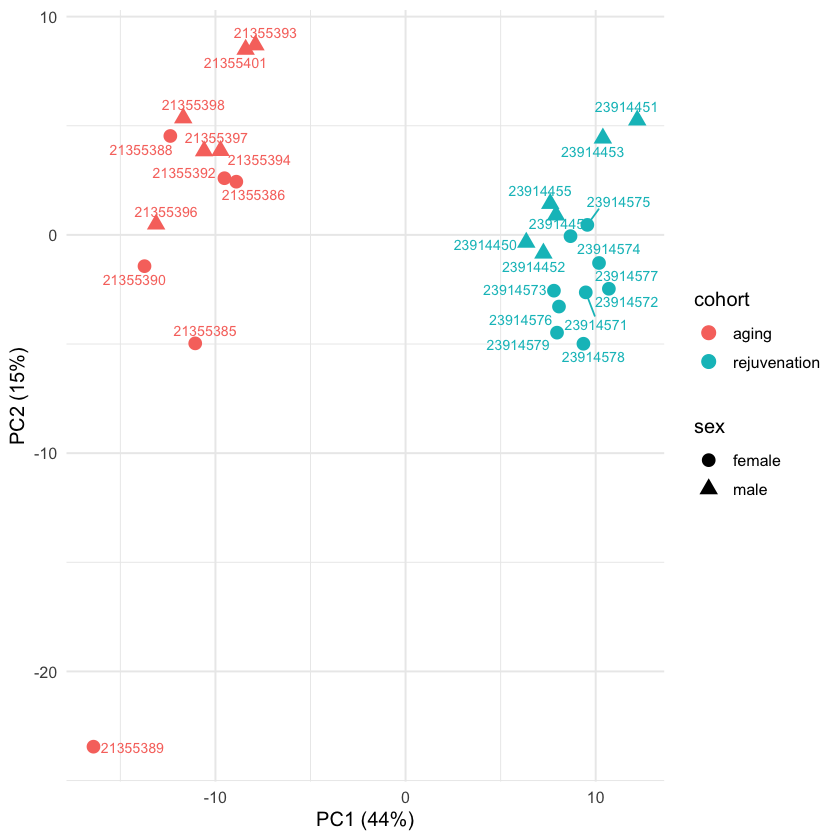

In [2]:
# vst = variance-stabilising transformation of counts, for plotting only
dds_all <- make_dds(txi, samples, ~ 1, min_n = 4)
pca_plot(dds_all, 'cohort', 'sex')

## 2 · Aging cohort (3, 18, 21 months)
### 2a · Outlier check
With all 12 mice, one 21-month female (SRR21355389) sits far from everyone on PC1.

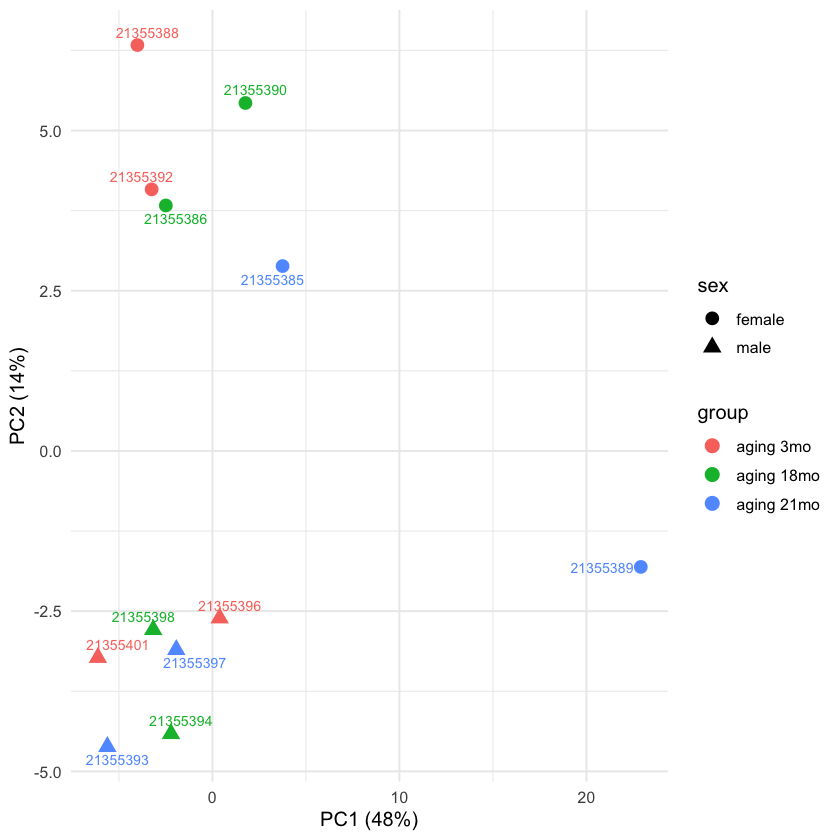

In [3]:
# aging mice only, all 12; PCA coloured by age group
s_age_all <- samples %>% filter(cohort == 'aging') %>% mutate(group = droplevels(group))
dds_age_all <- make_dds(txi, s_age_all, ~ sex + group, min_n = 4)
pca_plot(dds_age_all, 'group', 'sex')

In [4]:
# genes that most distinguish SRR21355389 from the other mice (vst difference)
outlier_genes(dds_age_all, 'SRR21355389', genes)

symbol,vst_diff
<chr>,<dbl>
S100a8,5.474019
Hbb-bs,5.471451
Hba-a2,5.353863
Hba-a1,5.126849
Hbb-bt,5.056503
S100a9,4.955572
Ngp,4.869030
Igkc,4.404684
Col1a1,4.224508


Its top genes are **haemoglobins** (Hbb, Hba: blood), **neutrophil** genes (S100a8/9, Ngp, Camp), **collagens** (Col1a1/2: meninges, vessels) and Igkc (antibody): contamination with blood and meningeal tissue (e.g. incomplete perfusion), not aging biology.

**Decision:** exclude it from the aging analysis. Change `EXCLUDE` below to keep it; 2b shows what the choice changes.

In [5]:
# the decision; set EXCLUDE <- character(0) to keep all 12 mice.
EXCLUDE <- 'SRR21355389'   # set to character(0) to keep all 12 aging samples
s_age <- s_age_all[!rownames(s_age_all) %in% EXCLUDE, ]
dds_age <- make_dds(txi, s_age, ~ sex + group, min_n = 3)

### 2b · DE results and sensitivity to the exclusion
`DEG` counts split into up (higher in the older group) and down.

In [6]:
# DE tables for 18 vs 3 and 21 vs 3 months; counts of up / down DEGs
age <- list(`18v3` = de_table(dds_age, c('group', 'aging 18mo', 'aging 3mo'), genes),
            `21v3` = de_table(dds_age, c('group', 'aging 21mo', 'aging 3mo'), genes))
bind_rows(lapply(age, n_deg), .id = 'contrast')

contrast,up,down
<chr>,<int>,<int>
18v3,109,30
21v3,79,53


In [7]:
# a = outlier excluded (used), b = all 12 mice: DEG counts, overlap, log2FC agreement (lfc_spearman)
# a = outlier excluded (used), b = all 12 samples
age_all_21v3 <- de_table(dds_age_all, c('group', 'aging 21mo', 'aging 3mo'), genes)
compare_de(age[['21v3']], age_all_21v3)

DEG_a,DEG_b,DEG_both,lfc_spearman
<int>,<int>,<int>,<dbl>
129,265,118,0.9811081


## 3 · Rejuvenation: aDR vs AL (females) and YMP vs PBS (males)

In [8]:
# one DESeq2 model per treatment (each against its own control); counts of up / down DEGs
s_adr <- samples %>% filter(group %in% c('AL', 'aDR')) %>% mutate(group = droplevels(group))
s_ymp <- samples %>% filter(group %in% c('PBS', 'YMP')) %>% mutate(group = droplevels(group))
dds_adr <- make_dds(txi, s_adr, ~ group, min_n = 4)
dds_ymp <- make_dds(txi, s_ymp, ~ group, min_n = 3)
rej <- list(aDR = de_table(dds_adr, c('group', 'aDR', 'AL'), genes),
            YMP = de_table(dds_ymp, c('group', 'YMP', 'PBS'), genes))
bind_rows(lapply(rej, n_deg), .id = 'contrast')

contrast,up,down
<chr>,<int>,<int>
aDR,65,78
YMP,19,19


## 4 · Save
One CSV per comparison with all tested genes (DESeq2 columns + gene symbol), read by later notebooks.

In [9]:
# writes results/de/<METHOD>/<comparison>.csv
res <- c(setNames(age, paste0('aging_', names(age))), rej)
invisible(imap(res, \(r, n) write_csv(r, file.path(ROOT, 'results/de', METHOD, paste0(n, '.csv')))))
list.files(file.path(ROOT, 'results/de', METHOD))

[1] "aDR.csv"        "aging_18v3.csv" "aging_21v3.csv" "YMP.csv"